# Дипломски рад

**Аутор:** Тијана Ђоковић

# 1. Припрема података

## 1.1. Учитавање и преглед скупа података

Учитавање података и укључивање потребних библиотека.

In [67]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, chi2_contingency

sns.set_style("whitegrid")


In [68]:
df = pd.read_excel("STEM.xlsx")
df.head()

,Timestamp,Пол:,Година рођења:,Похађам средњу школу:,Смер:,Разред:,Одрастао/ла сам у:,Основну школу сам завршио/ла у:,Занимање твоје мајке:,Стручна спрема твоје мајке:,...,Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Вршњаци],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Наставник],"Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Медији (телевизија, друштвене мреже, интернет, блогови итд)]",Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Добра проходност на факултет који желим да студирам по завршетку средње школе],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Интересовање за занимање којим желим да се бавим у будућности],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Школски психолог/педагог],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Разредни старешина],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Предметни наставник],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
0,2023-11-28 21:50:20.078,мушки,2007,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,2.0,већем граду,већем граду,preduzetnica,завршен факултет,...,1 - нимало,2 - мало,3 - средње,5 - изразито,5 - изразито,5 - изразито,1 - нимало,1 - нимало,1 - нимало,1 - нимало
1,2023-11-28 21:52:10.331,женски,2005,„Јован Јовановић Змај“ Нови Сад,природно-математички,4.0,варошици,варошици,Radnik,завршена виша школа,...,1 - нимало,4 - доста,4 - доста,5 - изразито,5 - изразито,4 - доста,1 - нимало,2 - мало,4 - доста,1 - нимало
2,2023-11-28 21:52:16.136,женски,2005,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,4.0,већем граду,већем граду,Lekar,завршен факултет,...,1 - нимало,1 - нимало,1 - нимало,2 - мало,4 - доста,1 - нимало,1 - нимало,1 - нимало,1 - нимало,1 - нимало
3,2023-11-28 21:52:17.193,женски,2007,„Јован Јовановић Змај“ Нови Сад,билингвално одељење (одељење у коме се део нас...,3.0,већем граду,већем граду,Diplomirani ekonomista,завршен факултет,...,3 - средње,4 - доста,2 - мало,5 - изразито,3 - средње,1 - нимало,5 - изразито,2 - мало,3 - средње,1 - нимало
4,2023-11-28 21:52:41.167,женски,2008,„Јован Јовановић Змај“ Нови Сад,природно-математички,1.0,селу,селу,Ekonomista,завршен факултет,...,1 - нимало,3 - средње,1 - нимало,3 - средње,4 - доста,4 - доста,4 - доста,5 - изразито,4 - доста,4 - доста


Основне информације о скупу података

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Columns: 105 entries, Timestamp to Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
dtypes: datetime64[ns](1), float64(1), int64(15), object(88)
memory usage: 856.5+ KB


In [70]:
df.describe()

,Timestamp,Година рођења:,Разред:,Најчешћа оцена из наведених предмета у основној школи ми је била: [Српски језик и књижевност],Најчешћа оцена из наведених предмета у основној школи ми је била: [Енглески језик],Најчешћа оцена из наведених предмета у основној школи ми је била: [2. страни језик],Најчешћа оцена из наведених предмета у основној школи ми је била: [Историја],Најчешћа оцена из наведених предмета у основној школи ми је била: [Географија],Најчешћа оцена из наведених предмета у основној школи ми је била: [Биологија],Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика],Најчешћа оцена из наведених предмета у основној школи ми је била: [Информатика],Најчешћа оцена из наведених предмета у основној школи ми је била: [Физика],Најчешћа оцена из наведених предмета у основној школи ми је била: [Хемија],Најчешћа оцена из наведених предмета у основној школи ми је била: [Музичка култура],Најчешћа оцена из наведених предмета у основној школи ми је била: [Ликовна култура],Најчешћа оцена из наведених предмета у основној школи ми је била: [Физичко васпитање],Најчешћа оцена из наведених предмета у основној школи ми је била: [Техника и технологија]
count,1044,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,2023-12-19 18:51:07.355917568,2006.895594,2.381322,4.766284,4.796935,4.800766,4.818008,4.819923,4.802682,4.546935,4.909004,4.585249,4.598659,4.954023,4.954981,4.966475,4.909004
min,2023-11-28 21:50:20.078000,2005.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2023-11-29 21:27:34.893999872,2006.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,4.000000,4.000000,5.000000,5.000000,5.000000,5.000000
50%,2023-12-14 09:02:53.044000,2007.000000,2.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
75%,2023-12-18 10:52:50.224750080,2008.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
max,2024-05-19 13:14:19.370000,2011.000000,8.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,1.211807,1.282004,0.549534,0.563299,0.556113,0.541137,0.554028,0.555071,0.824307,0.408861,0.771877,0.776475,0.333196,0.328984,0.306257,0.418136


In [71]:
df.shape

(1044, 105)

## 1.2. Дефинисање циљне променљиве (STEM vs NON-STEM)

Да ли ће ученик уписати СТЕМ или неки други смер?


In [72]:
stem_smerovi = [
    'природно-математички',
    'специјализовано одељење за ученике са посебним способностима за информатику',
    'специјализовано одељење за ученике са посебним способностима за математику',
    'специјализовано одељење за ученике са посебним способностима за биологију и хемију',
    'специјализовано одељење за ученике са посебним способностима за физику'
]


df['Смер - СТЕМ:'] = df['Смер:'].apply(lambda x: 1 if x in stem_smerovi else 0)
df['Смер - СТЕМ:'].value_counts()

Смер - СТЕМ:
0    610
1    434
Name: count, dtype: int64

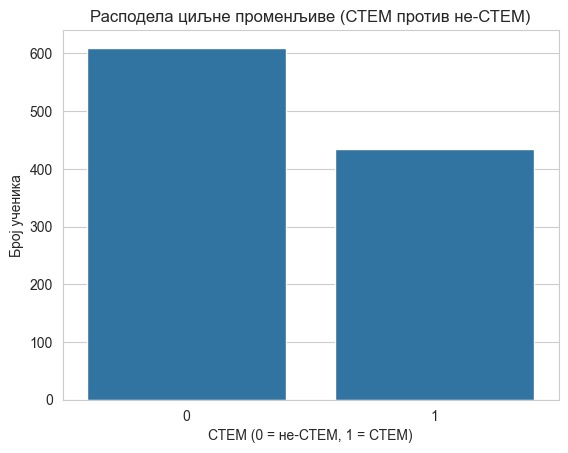

In [38]:
sns.countplot(x='Смер - СТЕМ:', data=df)
plt.xlabel('СТЕМ (0 = не-СТЕМ, 1 = СТЕМ)')
plt.ylabel('Број ученика')
plt.title('Расподела циљне променљиве (СТЕМ против не-СТЕМ)')
plt.show()

Колоне које су описне - дефинитивно не могу да утичу у оваквом изворном стању. Овакви подаци захтевају сложенију обраду и у овом раду их нећемо користити у процесу моделовања.

То су колоне:
- Timestamp
- Занимање твоје мајке:
- Занимање твог оца:
- Зашто сте изабрали да упишите Гимназију?
- Зашто сте изабрали да упишете овај смер?


In [73]:
X = df.drop(columns=['Timestamp', 'Занимање твоје мајке:', 'Занимање твог оца:', 'Зашто сте изабрали да упишите Гимназију?', 'Зашто сте изабрали да упишете овај смер?'])
y = df['Смер - СТЕМ:']

print("Колоне у табели:")
print(X.columns.tolist())

Колоне у табели:
['Пол:', 'Година рођења:', 'Похађам средњу школу:', 'Смер:', 'Разред:', 'Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):', 'Какав си био/ла ђак у основној школи?', 'Најомиљенији предмет:', 'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):', 'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):', 'Колико ти је поједини предмет био тежак у основној школи?  [Српски језик и књижевност]', 'Колико ти је поједини предмет био тежак у основној школи?  [Енглески језик]', 'Колико ти је поједини предмет био тежак у основној школи?  [2. страни језик]', 'Колико ти је поједини предмет био тежак у основној школи?  [Историја]', 'Колико ти је поједини предмет био тежак у основној школи?  [Географија]', 'Колико ти је поједини предмет био тежак у основној школи?  [Биологија]', 'Колико ти је поједини предмет био тежак 

## Анализа неких предмета који припадају СТЕМ областима 

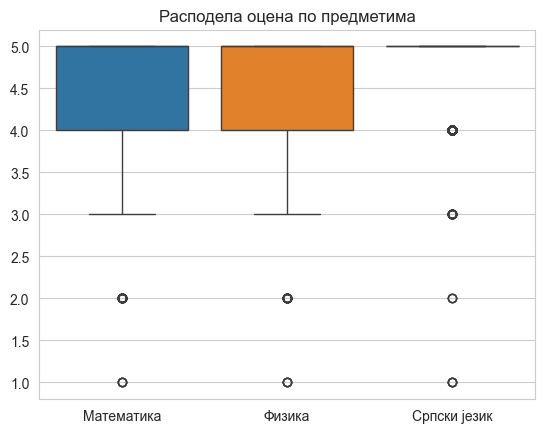

In [74]:
data = X[[
'Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика]',
'Најчешћа оцена из наведених предмета у основној школи ми је била: [Физика]',
'Најчешћа оцена из наведених предмета у основној школи ми је била: [Српски језик и књижевност]'
]]

sns.boxplot(data=data)

plt.xticks(
    ticks=[0, 1, 2],
    labels=['Математика', 'Физика', 'Српски језик']
)

plt.title('Расподела оцена по предметима')
plt.show()

## Анализа категоријских обележја

In [75]:
X['Пол:'].value_counts()

Пол:
женски    715
мушки     329
Name: count, dtype: int64

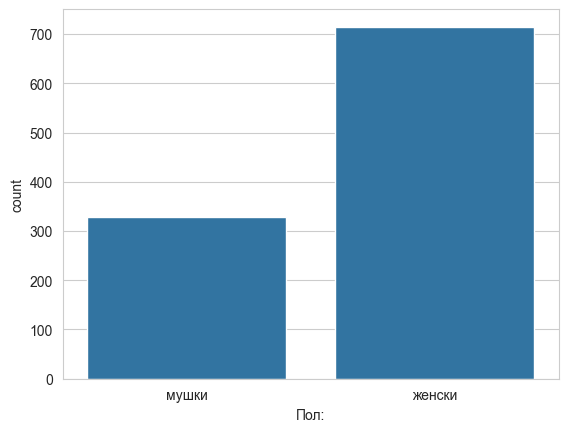

In [76]:
sns.countplot(x='Пол:', data=X)
plt.show()

In [77]:
X['Одрастао/ла сам у:'].value_counts()

Одрастао/ла сам у:
већем граду    712
селу           139
мањем граду     98
варошици        95
Name: count, dtype: int64

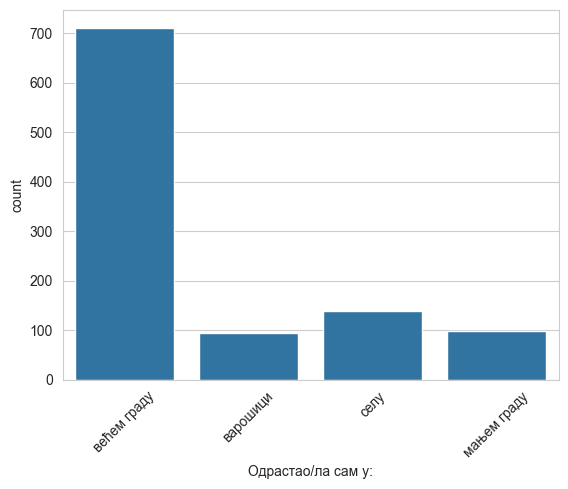

In [78]:
sns.countplot(x='Одрастао/ла сам у:', data=X)
plt.xticks(rotation=45)
plt.show()

## Однос категоријских обележја и СТЕМ опредељења

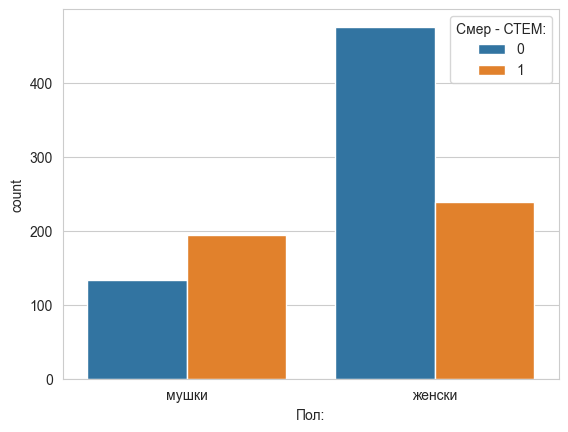

In [79]:
sns.countplot(x='Пол:', hue='Смер - СТЕМ:', data=X)
plt.show()

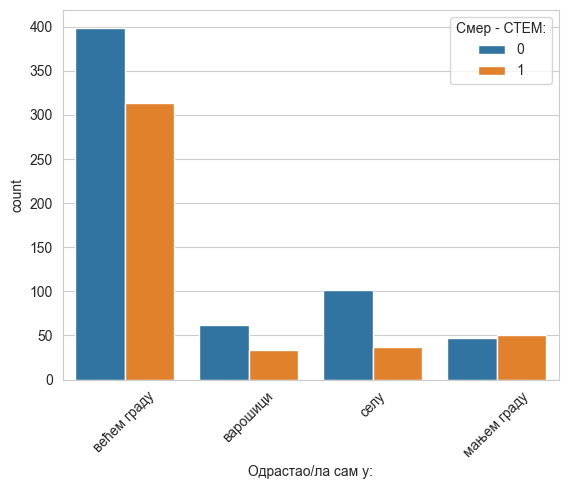

In [80]:
sns.countplot(x='Одрастао/ла сам у:', hue='Смер - СТЕМ:', data=X)
plt.xticks(rotation=45)
plt.show()

## Боксплот

C:\Users\hplay\AppData\Local\Temp\ipykernel_9472\1489012759.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['НЕ-СТЕМ', 'СТЕМ'])


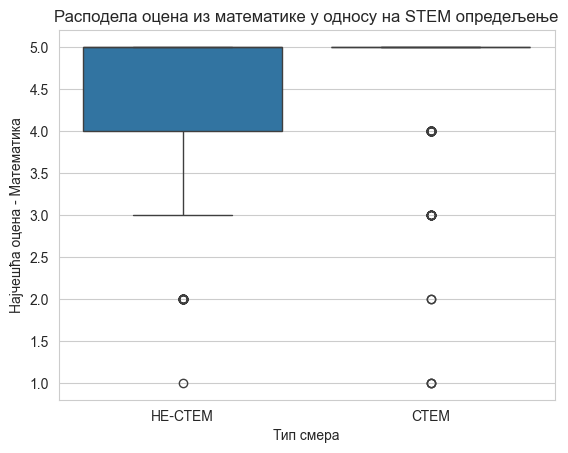

In [81]:
ax = sns.boxplot(
    x='Смер - СТЕМ:',
    y='Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика]',
    data=X
)

# X оса (0 → НЕ-СТЕМ, 1 → СТЕМ)
ax.set_xticklabels(['НЕ-СТЕМ', 'СТЕМ'])

# Y оса (назив)
plt.ylabel('Најчешћа оцена - Математика')

# X оса (назив)
plt.xlabel('Тип смера')

plt.title('Расподела оцена из математике у односу на STEM опредељење')

plt.show()

## Корелациона матрица

Неке одговоре чији се одговори базирају на Ликертовој скали ћемо енкодирати како би могли да креирамо корелациону матрицу. Користићемо ординално енкодирање.

In [82]:
def extract_number(x):
    if pd.isna(x):
        return x
    return int(str(x).split('-')[0].strip())


likert_cols = [col for col in X.columns if 'Колико ти је' in col or 'Процени' in col]

for col in likert_cols:
    X[col] = X[col].apply(extract_number)

In [83]:
selected_columns = [
    'Смер - СТЕМ:',
    'Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика]',
    'Најчешћа оцена из наведених предмета у основној школи ми је била: [Физика]',
    'Најчешћа оцена из наведених предмета у основној школи ми је била: [Информатика]',
    'Колико ти је поједини предмет био занимљив у основној школи?  [Математика]',
    'Колико ти је поједини предмет био занимљив у основној школи?  [Физика]',
    'Колико ти је поједини предмет био тежак у основној школи?  [Математика]',
    'Колико ти је поједини предмет био тежак у основној школи?  [Физика]'
]

corr = X[selected_columns].corr()

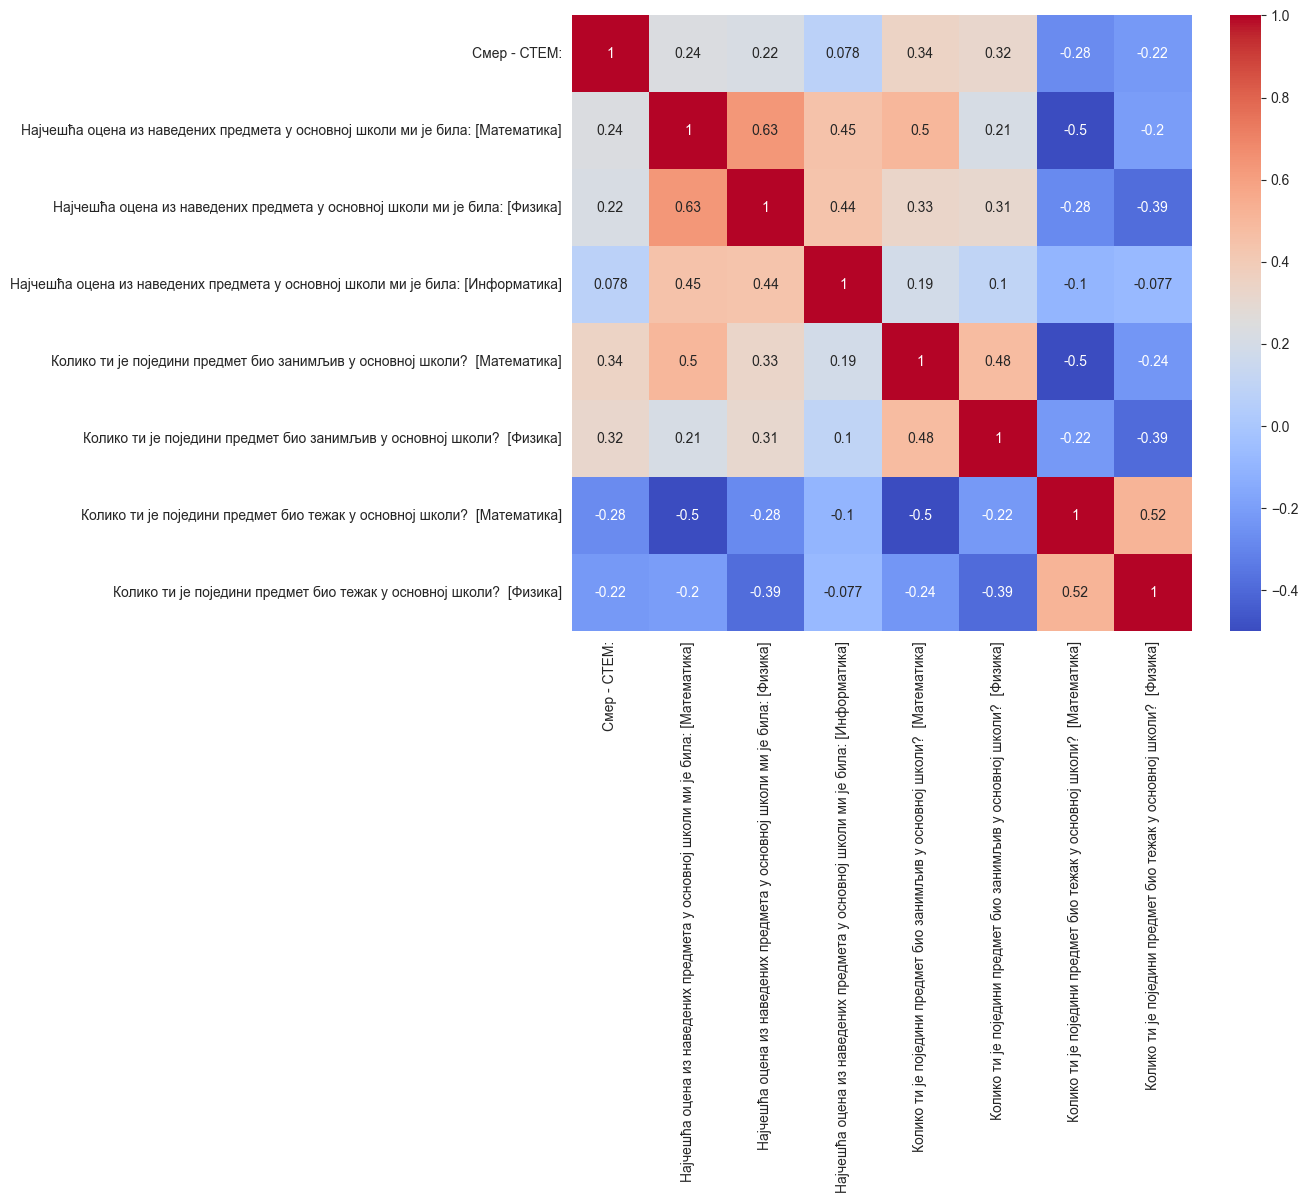

In [84]:
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

## Статистички тестови

t-test

In [85]:
stem = X[X['Смер - СТЕМ:'] == 1]['Колико ти је поједини предмет био занимљив у основној школи?  [Математика]']
non_stem = X[X['Смер - СТЕМ:'] == 0]['Колико ти је поједини предмет био занимљив у основној школи?  [Математика]']

ttest_ind(stem, non_stem)

TtestResult(statistic=np.float64(11.857822831447494), pvalue=np.float64(1.6267203357737002e-30), df=np.float64(1042.0))

chi-square

In [86]:
stem = X[X['Смер - СТЕМ:'] == 1]['Колико ти је поједини предмет био занимљив у основној школи?  [Математика]']
non_stem = X[X['Смер - СТЕМ:'] == 0]['Колико ти је поједини предмет био занимљив у основној школи?  [Математика]']

ttest_ind(stem, non_stem)

TtestResult(statistic=np.float64(11.857822831447494), pvalue=np.float64(1.6267203357737002e-30), df=np.float64(1042.0))